In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("../data/synthetic")
OUTPUT_DIR = Path("../data/processed")
FIGURE_DIR = Path("../reports/figures")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
restaurants = pd.read_csv(DATA_DIR / "restaurants.csv")
orders = pd.read_csv(DATA_DIR / "orders.csv")
deliveries = pd.read_csv(DATA_DIR / "deliveries.csv")
drivers = pd.read_csv(DATA_DIR / "drivers.csv")
reviews = pd.read_csv(DATA_DIR / "reviews.csv")
payments = pd.read_csv(DATA_DIR / "payments.csv")

datasets = {
    "Customers": customers,
    "Restaurants": restaurants,
    "Orders": orders,
    "Deliveries": deliveries,
    "Drivers": drivers,
    "Reviews": reviews,
    "Payments": payments
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (1000, 5)
Restaurants: (100, 6)
Orders: (10000, 14)
Deliveries: (9358, 6)
Drivers: (200, 4)
Reviews: (7000, 7)
Payments: (10000, 6)


In [4]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isnull().sum().sum())
    print(df.head(3))


--- Customers ---
Duplicate rows: 0
Missing values: 0
  customer_id  age     city membership signup_date
0       C0001   22    Delhi    Regular  2024-08-20
1       C0002   55   Mumbai    Regular  2025-09-08
2       C0003   49  Chennai    Regular  2024-01-26

--- Restaurants ---
Duplicate rows: 0
Missing values: 0
  restaurant_id restaurant_name       city   category  restaurant_rating  \
0          R001  Restaurant_001  Hyderabad  Fast Food                3.8   
1          R002  Restaurant_002  Hyderabad  Fast Food                4.3   
2          R003  Restaurant_003     Mumbai    Chinese                3.9   

   avg_prep_time_minutes  
0                     36  
1                     31  
2                     30  

--- Orders ---
Duplicate rows: 0
Missing values: 0
  order_id customer_id restaurant_id      order_timestamp  order_amount  \
0   O00001       C0568          R064  2026-01-22 21:53:00        453.07   
1   O00002       C0500          R074  2026-06-24 20:16:00        357.

In [5]:
print(orders.dtypes)
print(orders["order_timestamp"].head())

order_id                     str
customer_id                  str
restaurant_id                str
order_timestamp              str
order_amount             float64
number_of_items            int64
delivery_distance_km     float64
prep_time_minutes          int64
delivery_time_minutes      int64
traffic                      str
weather                      str
is_weekend                 int64
peak_period_weight       float64
order_status                 str
dtype: object
0    2026-01-22 21:53:00
1    2026-06-24 20:16:00
2    2026-04-03 03:15:00
3    2026-04-10 13:00:00
4    2026-03-16 11:02:00
Name: order_timestamp, dtype: str


In [6]:
orders["order_timestamp"] = pd.to_datetime(
    orders["order_timestamp"],
    errors="coerce"
)

print("Invalid timestamps:", orders["order_timestamp"].isna().sum())

Invalid timestamps: 0


In [7]:
delivered_orders = orders[
    orders["order_status"] == "Delivered"
].copy()

# Customer order behavior
customer_features = delivered_orders.groupby(
    "customer_id"
).agg(
    total_orders=("order_id", "nunique"),
    avg_order_value=("order_amount", "mean"),
    total_spending=("order_amount", "sum"),
    weekend_orders=("is_weekend", "sum"),
    late_night_orders=(
        "order_timestamp",
        lambda x: x.dt.hour.isin([22, 23, 0, 1, 2, 3, 4]).sum()
    )
).reset_index()

# Average rating given by customers
customer_ratings = reviews.groupby(
    "customer_id"
).agg(
    avg_rating_given=("review_rating", "mean")
).reset_index()

customer_features = customer_features.merge(
    customer_ratings,
    on="customer_id",
    how="left"
)

# Ordering frequency: orders per observed day
customer_features["ordering_frequency"] = (
    customer_features["total_orders"] / 180
)

# Fill missing ratings for customers without reviews
customer_features["avg_rating_given"] = (
    customer_features["avg_rating_given"].fillna(
        customer_features["avg_rating_given"].median()
    )
)

customer_features.head()

,customer_id,total_orders,avg_order_value,total_spending,weekend_orders,late_night_orders,avg_rating_given,ordering_frequency
0,C0001,7,490.475714,3433.33,1,0,2.666667,0.038889
1,C0002,6,618.010000,3708.06,3,1,3.000000,0.033333
2,C0003,10,620.250000,6202.50,2,3,3.000000,0.055556
3,C0004,10,763.736000,7637.36,1,1,3.666667,0.055556
4,C0005,9,567.401111,5106.61,2,4,2.250000,0.050000


In [8]:
restaurant_features = orders.groupby(
    "restaurant_id"
).agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("order_amount", "sum"),
    avg_prep_time=("prep_time_minutes", "mean"),
    cancellation_rate=(
        "order_status",
        lambda x: (x == "Cancelled").mean() * 100
    )
).reset_index()

# Average restaurant rating from the restaurant dataset
restaurant_features = restaurant_features.merge(
    restaurants[["restaurant_id", "restaurant_rating"]],
    on="restaurant_id",
    how="left"
)

# Average delivery time, using completed deliveries
avg_delivery = deliveries.groupby(
    "order_id"
)["delivery_time_minutes"].mean()

delivery_lookup = orders[["order_id", "restaurant_id"]].copy()
delivery_lookup["delivery_time_minutes"] = (
    delivery_lookup["order_id"].map(avg_delivery)
)

restaurant_delivery = delivery_lookup.groupby(
    "restaurant_id"
).agg(
    avg_delivery_time=("delivery_time_minutes", "mean")
).reset_index()

restaurant_features = restaurant_features.merge(
    restaurant_delivery,
    on="restaurant_id",
    how="left"
)

restaurant_features.head()

,restaurant_id,total_orders,total_revenue,avg_prep_time,cancellation_rate,restaurant_rating,avg_delivery_time
0,R001,108,74456.51,36.0,5.555556,3.8,63.509804
1,R002,87,52287.67,31.0,8.045977,4.3,56.812500
2,R003,104,66256.75,30.0,5.769231,3.9,55.561224
3,R004,116,73160.52,26.0,5.172414,4.5,53.100000
4,R005,91,57619.54,10.0,12.087912,3.1,36.062500


In [9]:
customer_features.to_csv(
    OUTPUT_DIR / "customer_features.csv",
    index=False
)

restaurant_features.to_csv(
    OUTPUT_DIR / "restaurant_features.csv",
    index=False
)

print("Customer feature shape:", customer_features.shape)
print("Restaurant feature shape:", restaurant_features.shape)
print("Feature-engineered datasets saved.")

Customer feature shape: (1000, 8)
Restaurant feature shape: (100, 7)
Feature-engineered datasets saved.


FEATURE SCALING AND CLUSTERING PREPARATION 

In [10]:
# Select customer features; exclude customer_id
customer_model_features = customer_features.drop(
    columns=["customer_id"]
).copy()

# Select restaurant features; exclude restaurant_id
restaurant_model_features = restaurant_features.drop(
    columns=["restaurant_id"]
).copy()

# Handle any remaining missing and infinite values
customer_model_features = customer_model_features.replace(
    [np.inf, -np.inf], np.nan
)
restaurant_model_features = restaurant_model_features.replace(
    [np.inf, -np.inf], np.nan
)

customer_model_features = customer_model_features.fillna(
    customer_model_features.median()
)
restaurant_model_features = restaurant_model_features.fillna(
    restaurant_model_features.median()
)

# Scale the features
customer_scaler = StandardScaler()
restaurant_scaler = StandardScaler()

X_customers = customer_scaler.fit_transform(
    customer_model_features
)
X_restaurants = restaurant_scaler.fit_transform(
    restaurant_model_features
)

print("Customer matrix:", X_customers.shape)
print("Restaurant matrix:", X_restaurants.shape)

Customer matrix: (1000, 7)
Restaurant matrix: (100, 6)


OPTMAL NO. OF CLUSTERS

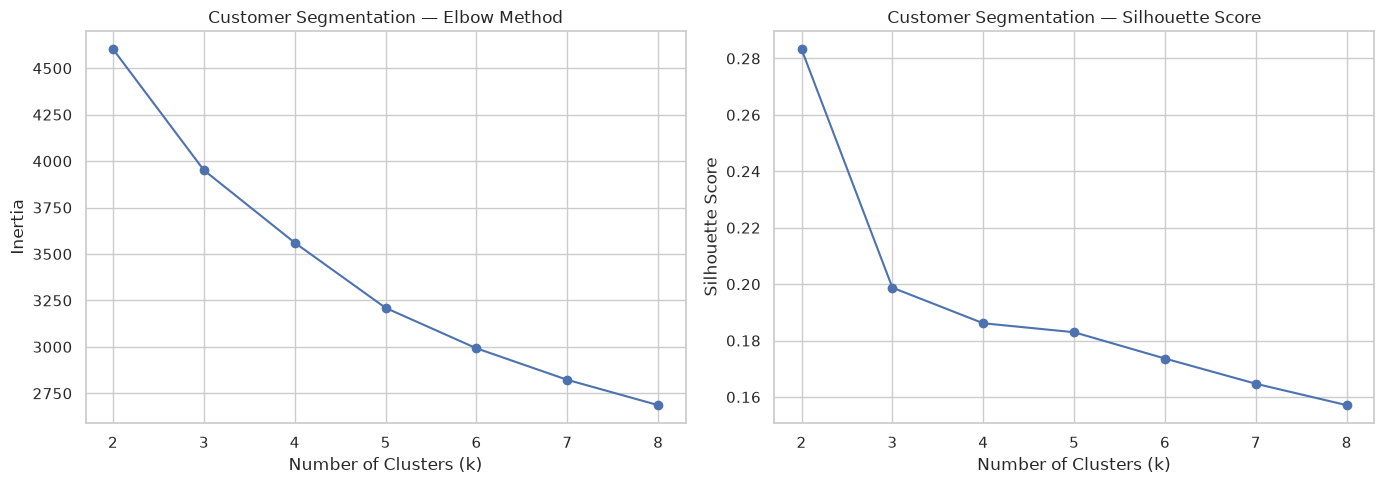

Customer silhouette scores:
k=2: 0.2833
k=3: 0.1987
k=4: 0.1861
k=5: 0.1830
k=6: 0.1736
k=7: 0.1647
k=8: 0.1571


In [11]:
k_values = range(2, 9)

customer_inertias = []
customer_silhouettes = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_customers)

    customer_inertias.append(model.inertia_)
    customer_silhouettes.append(
        silhouette_score(X_customers, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(k_values), customer_inertias, marker="o"
)
axes[0].set_title("Customer Segmentation — Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values), customer_silhouettes, marker="o"
)
axes[1].set_title("Customer Segmentation — Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print("Customer silhouette scores:")
for k, score in zip(k_values, customer_silhouettes):
    print(f"k={k}: {score:.4f}")

In [19]:
customer_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

customer_features["customer_cluster"] = (
    customer_kmeans.fit_predict(X_customers)
)

print(
    customer_features["customer_cluster"]
    .value_counts()
    .sort_index()
)

customer_features.to_csv(
    OUTPUT_DIR / "customer_features.csv",
    index=False
)

customer_cluster
0    487
1    513
Name: count, dtype: int64


In [20]:
restaurant_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

restaurant_features["restaurant_cluster"] = (
    restaurant_kmeans.fit_predict(X_restaurants)
)

print(
    restaurant_features["restaurant_cluster"]
    .value_counts()
    .sort_index()
)

restaurant_features.to_csv(
    OUTPUT_DIR / "restaurant_features.csv",
    index=False
)

restaurant_cluster
0    50
1    50
Name: count, dtype: int64


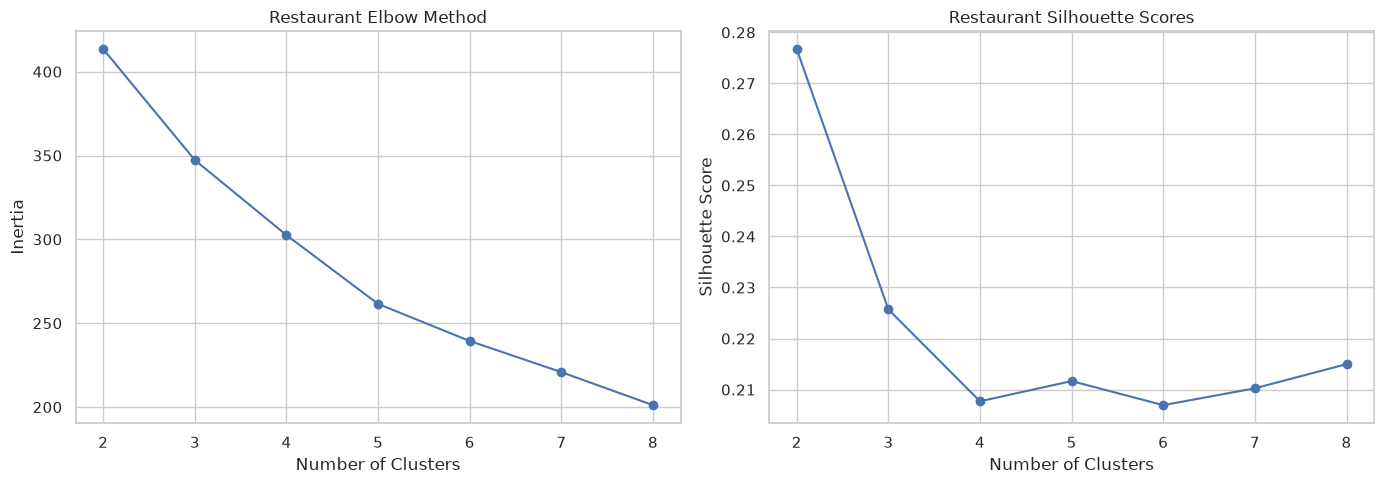

k=2: silhouette=0.2767
k=3: silhouette=0.2257
k=4: silhouette=0.2077
k=5: silhouette=0.2117
k=6: silhouette=0.2069
k=7: silhouette=0.2102
k=8: silhouette=0.2150


In [21]:
k_values = range(2, 9)

restaurant_inertias = []
restaurant_silhouettes = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_restaurants)

    restaurant_inertias.append(model.inertia_)
    restaurant_silhouettes.append(
        silhouette_score(X_restaurants, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), restaurant_inertias, marker="o")
axes[0].set_title("Restaurant Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), restaurant_silhouettes, marker="o")
axes[1].set_title("Restaurant Silhouette Scores")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "restaurant_elbow_silhouette.png",
            dpi=150, bbox_inches="tight")
plt.show()

for k, score in zip(k_values, restaurant_silhouettes):
    print(f"k={k}: silhouette={score:.4f}")

In [22]:
customer_dbscan = DBSCAN(
    eps=1.5,
    min_samples=10
)

customer_dbscan_labels = customer_dbscan.fit_predict(
    X_customers
)

customer_features["customer_dbscan_cluster"] = (
    customer_dbscan_labels
)

print(
    customer_features["customer_dbscan_cluster"]
    .value_counts()
    .sort_index()
)

n_clusters = len(set(customer_dbscan_labels)) - (
    1 if -1 in customer_dbscan_labels else 0
)

n_noise = (customer_dbscan_labels == -1).sum()

print("DBSCAN clusters:", n_clusters)
print("Noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(X_customers) * 100, 2), "%")

customer_dbscan_cluster
-1     27
 0    973
Name: count, dtype: int64
DBSCAN clusters: 1
Noise points: 27
Noise percentage: 2.7 %


In [23]:
restaurant_dbscan = DBSCAN(
    eps=1.5,
    min_samples=5
)

restaurant_dbscan_labels = restaurant_dbscan.fit_predict(
    X_restaurants
)

restaurant_features["restaurant_dbscan_cluster"] = (
    restaurant_dbscan_labels
)

print(
    restaurant_features["restaurant_dbscan_cluster"]
    .value_counts()
    .sort_index()
)

restaurant_dbscan_cluster
-1    18
 0    82
Name: count, dtype: int64


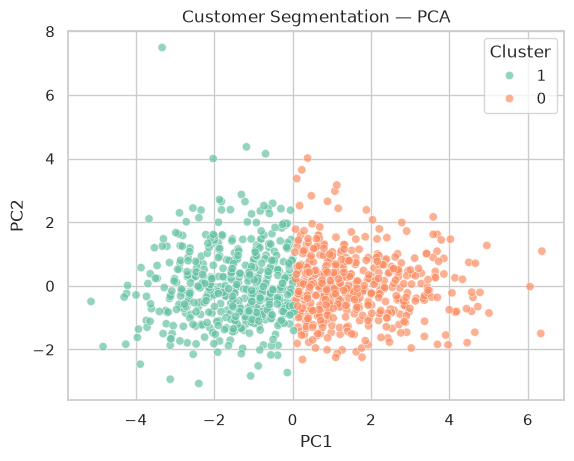

Customer PCA variance explained: 0.6866


In [24]:
customer_pca = PCA(n_components=2)

customer_pca_data = customer_pca.fit_transform(X_customers)

customer_pca_df = pd.DataFrame({
    "PC1": customer_pca_data[:, 0],
    "PC2": customer_pca_data[:, 1],
    "Cluster": customer_features["customer_cluster"].astype(str)
})

sns.scatterplot(
    data=customer_pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segmentation — PCA")
plt.savefig(FIGURE_DIR / "customer_pca.png",
            dpi=150, bbox_inches="tight")
plt.show()

print(
    "Customer PCA variance explained:",
    customer_pca.explained_variance_ratio_.sum().round(4)
)

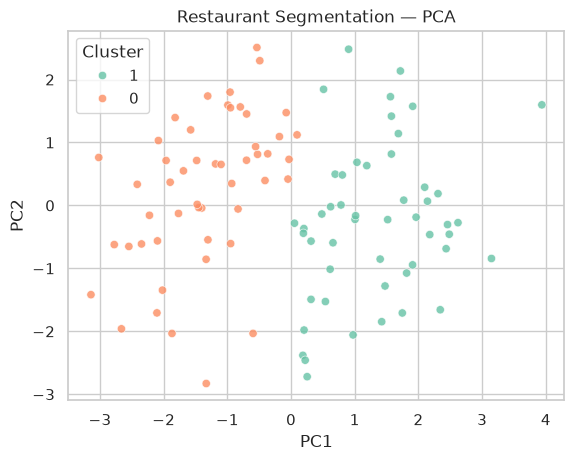

Restaurant PCA variance explained: 0.6679


In [25]:
restaurant_pca = PCA(n_components=2)

restaurant_pca_data = restaurant_pca.fit_transform(X_restaurants)

restaurant_pca_df = pd.DataFrame({
    "PC1": restaurant_pca_data[:, 0],
    "PC2": restaurant_pca_data[:, 1],
    "Cluster": restaurant_features["restaurant_cluster"].astype(str)
})

sns.scatterplot(
    data=restaurant_pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    alpha=0.8
)

plt.title("Restaurant Segmentation — PCA")
plt.savefig(FIGURE_DIR / "restaurant_pca.png",
            dpi=150, bbox_inches="tight")
plt.show()

print(
    "Restaurant PCA variance explained:",
    restaurant_pca.explained_variance_ratio_.sum().round(4)
)

In [26]:
customer_profile = customer_features.groupby(
    "customer_cluster"
).agg(
    customer_count=("customer_id", "count"),
    avg_orders=("total_orders", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_total_spending=("total_spending", "mean"),
    avg_ordering_frequency=("ordering_frequency", "mean"),
    avg_rating_given=("avg_rating_given", "mean"),
    avg_weekend_orders=("weekend_orders", "mean"),
    avg_late_night_orders=("late_night_orders", "mean")
).round(2)

display(customer_profile)

,customer_count,avg_orders,avg_order_value,avg_total_spending,avg_ordering_frequency,avg_rating_given,avg_weekend_orders,avg_late_night_orders
customer_cluster,,,,,,,,
0,487,11.83,644.24,7574.04,0.07,3.00,3.49,3.75
1,513,7.01,621.17,4335.50,0.04,2.98,1.80,1.79


In [27]:
restaurant_profile = restaurant_features.groupby(
    "restaurant_cluster"
).agg(
    restaurant_count=("restaurant_id", "count"),
    avg_orders=("total_orders", "mean"),
    avg_revenue=("total_revenue", "mean"),
    avg_rating=("restaurant_rating", "mean"),
    avg_prep_time=("avg_prep_time", "mean"),
    avg_cancellation_rate=("cancellation_rate", "mean"),
    avg_delivery_time=("avg_delivery_time", "mean")
).round(2)

display(restaurant_profile)

,restaurant_count,avg_orders,avg_revenue,avg_rating,avg_prep_time,avg_cancellation_rate,avg_delivery_time
restaurant_cluster,,,,,,,
0,50,94.72,59115.21,4.07,17.32,7.19,43.43
1,50,105.28,67364.01,4.16,31.30,5.74,57.49


In [28]:
def test_dbscan(X, eps_values, min_samples):
    results = []

    for eps in eps_values:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(X)

        n_clusters = len(set(labels) - {-1})
        n_noise = int((labels == -1).sum())

        # Silhouette is only meaningful with 2+ clusters
        # and when noise points are excluded.
        non_noise = labels != -1
        valid_labels = labels[non_noise]

        if (
            len(set(valid_labels)) >= 2
            and non_noise.sum() > len(set(valid_labels))
        ):
            score = silhouette_score(
                X[non_noise],
                valid_labels
            )
        else:
            score = np.nan

        results.append({
            "eps": eps,
            "clusters": n_clusters,
            "noise_points": n_noise,
            "noise_percent": round(
                n_noise / len(X) * 100, 2
            ),
            "silhouette_excluding_noise": (
                round(score, 4)
                if not np.isnan(score) else np.nan
            )
        })

    return pd.DataFrame(results)


customer_dbscan_results = test_dbscan(
    X_customers,
    eps_values=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0],
    min_samples=10
)

restaurant_dbscan_results = test_dbscan(
    X_restaurants,
    eps_values=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0],
    min_samples=5
)

print("Customer DBSCAN tuning:")
display(customer_dbscan_results)

print("Restaurant DBSCAN tuning:")
display(restaurant_dbscan_results)

Customer DBSCAN tuning:


,eps,clusters,noise_points,noise_percent,silhouette_excluding_noise
0,0.50,0,1000,100.0,NaN
1,0.75,6,908,90.8,0.211
2,1.00,1,371,37.1,NaN
3,1.25,1,121,12.1,NaN
4,1.50,1,27,2.7,NaN
5,2.00,1,4,0.4,NaN


Restaurant DBSCAN tuning:


,eps,clusters,noise_points,noise_percent,silhouette_excluding_noise
0,0.50,0,100,100.0,NaN
1,0.75,0,100,100.0,NaN
2,1.00,2,88,88.0,0.5114
3,1.25,3,45,45.0,0.3826
4,1.50,1,18,18.0,NaN
5,2.00,1,1,1.0,NaN


In [29]:
customer_features.to_csv(
    OUTPUT_DIR / "customer_features.csv",
    index=False
)

restaurant_features.to_csv(
    OUTPUT_DIR / "restaurant_features.csv",
    index=False
)

customer_profile.to_csv(
    OUTPUT_DIR / "customer_cluster_profiles.csv"
)

restaurant_profile.to_csv(
    OUTPUT_DIR / "restaurant_cluster_profiles.csv"
)

customer_dbscan_results.to_csv(
    OUTPUT_DIR / "customer_dbscan_comparison.csv",
    index=False
)

restaurant_dbscan_results.to_csv(
    OUTPUT_DIR / "restaurant_dbscan_comparison.csv",
    index=False
)

print("Day 2 segmentation results saved.")

Day 2 segmentation results saved.


In [30]:
customer_cluster_names = {
    0: "High-Frequency, High-Value Customers",
    1: "Lower-Frequency Customers"
}

restaurant_cluster_names = {
    0: "Faster-Preparation Restaurants",
    1: "Higher-Volume Restaurants"
}

customer_features["customer_segment"] = (
    customer_features["customer_cluster"]
    .map(customer_cluster_names)
)

restaurant_features["restaurant_segment"] = (
    restaurant_features["restaurant_cluster"]
    .map(restaurant_cluster_names)
)

customer_features.to_csv(
    OUTPUT_DIR / "customer_features.csv",
    index=False
)

restaurant_features.to_csv(
    OUTPUT_DIR / "restaurant_features.csv",
    index=False
)

display(
    customer_features[
        ["customer_id", "customer_cluster", "customer_segment"]
    ].head()
)

display(
    restaurant_features[
        ["restaurant_id", "restaurant_cluster", "restaurant_segment"]
    ].head()
)

,customer_id,customer_cluster,customer_segment
0,C0001,1,Lower-Frequency Customers
1,C0002,1,Lower-Frequency Customers
2,C0003,0,"High-Frequency, High-Value Customers"
3,C0004,1,Lower-Frequency Customers
4,C0005,1,Lower-Frequency Customers


,restaurant_id,restaurant_cluster,restaurant_segment
0,R001,1,Higher-Volume Restaurants
1,R002,0,Faster-Preparation Restaurants
2,R003,1,Higher-Volume Restaurants
3,R004,1,Higher-Volume Restaurants
4,R005,0,Faster-Preparation Restaurants


In [31]:
customer_loadings = pd.DataFrame(
    customer_pca.components_.T,
    index=customer_model_features.columns,
    columns=["PC1", "PC2"]
)

display(
    customer_loadings
    .assign(PC1_abs=lambda x: x["PC1"].abs())
    .sort_values("PC1_abs", ascending=False)
    .drop(columns="PC1_abs")
)

,PC1,PC2
total_orders,0.506108,-0.098502
ordering_frequency,0.506108,-0.098502
total_spending,0.483690,0.306000
late_night_orders,0.365050,-0.126836
weekend_orders,0.341037,-0.174342
avg_order_value,0.064064,0.911098
avg_rating_given,0.008966,-0.101865


In [32]:
restaurant_loadings = pd.DataFrame(
    restaurant_pca.components_.T,
    index=restaurant_model_features.columns,
    columns=["PC1", "PC2"]
)

display(
    restaurant_loadings
    .assign(PC1_abs=lambda x: x["PC1"].abs())
    .sort_values("PC1_abs", ascending=False)
    .drop(columns="PC1_abs")
)

,PC1,PC2
avg_prep_time,0.497463,-0.489819
avg_delivery_time,0.496401,-0.491055
total_revenue,0.478182,0.501844
total_orders,0.466905,0.516124
cancellation_rate,-0.236309,-0.026330
restaurant_rating,0.060136,0.004172


### PCA Visualization and Interpretation

PCA was used to project the scaled customer and restaurant feature spaces into two dimensions for visual inspection of the K-Means clusters.

**Customer segmentation:** The two clusters show partial separation along the first principal component, with some overlap around the center. This suggests that the customer groups have different behavioral patterns but are not completely distinct. Cluster profiling identified differences in average order frequency and total spending, enabling preliminary business interpretations of the segments.

**Restaurant segmentation:** The two restaurant clusters appear separated primarily along the first principal component. The first two principal components explain 66.79% of the variance in the scaled restaurant features, providing a useful, though incomplete, representation of the original feature space. Cluster profiles indicate differences in order volume, revenue, preparation time and cancellation rate.

**Limitation:** PCA is a visualization technique and does not independently establish cluster quality. The silhouette scores, cluster profiles and original feature distributions should also be considered. Since the data is synthetic, the findings should be treated as exploratory rather than as verified patterns in actual Uber Eats operations.